# Modeling the Impact of COVID-19 Disruption on Clinical Trial Completion by Location

**An Exercise-Style Exploration of Assumptions, Data Quality, and Hypothesis Testing**

---

## Background: Project Overview

*[To be filled in: Provide context on the research question, data sources, and study population]*

## Background: LadybugDB and the Graph Schema

*[To be filled in: Explain LadybugDB, Kuzu, the graph structure, and how AACT data is represented as nodes and edges]*

---
## Section 1: Setup and Utilities

### Imports and Configuration

In [1]:
!pip install seaborn
!pip install statsmodels
import real_ladybug as lb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as ss
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.imputation.mice import MICE, MICEData
import json
import math
from itertools import combinations
import os
import warnings

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print('✓ All libraries imported successfully')

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
✓ All libraries imported successfully


### Database Connection

Connect to LadybugDB (Kuzu) and PostgreSQL AACT source.

In [2]:
db   = lb.Database('/database/database.kz', read_only=True)
conn = lb.Connection(db)

def q(cypher):
    """Run a Cypher query; strip node-alias prefixes (s.field -> field)."""
    df = conn.execute(cypher).get_as_df()
    df.columns = [c.split('.')[-1] if '.' in c else c for c in df.columns]
    return df

def execute_cypher(query, description=""):
    if description:
        print(f"\n📊 {description}")
    return q(query)

print('✓ LadybugDB connected (read-only)')

# ── PostgreSQL / AACT ctgov schema ─────────────────────────────────────
from sqlalchemy import create_engine as _sa_engine
_DB_HOST = os.getenv("DB_HOST", "postgres")
_DB_PORT = os.getenv("DB_PORT", "5432")
_DB_NAME = os.getenv("DB_NAME", "aactdb")
_DB_USER = os.getenv("DB_USER", "postgres")
_DB_PASS = os.getenv("DB_PASS", "postgres")

pg_engine = _sa_engine(
    f"postgresql+psycopg2://{_DB_USER}:{_DB_PASS}@{_DB_HOST}:{_DB_PORT}/{_DB_NAME}"
)

def sql(query, **kwargs):
    """Run a SQL query against ctgov schema; returns a DataFrame."""
    return pd.read_sql(query, pg_engine, **kwargs)

print('✓ PostgreSQL (aact-postgres) connected')


✓ LadybugDB connected (read-only)
✓ PostgreSQL (aact-postgres) connected


### Utility Functions from CSCI-83 Coursework

Borrowed and adapted from completed notebooks (Chapters 21, 25, etc.)

In [3]:
# --- Residual and Distributional Analysis ---

def rmse_mae(df, residuals='resids'):
    """Compute RMSE and MAE of residuals."""
    median = round(df.loc[:, residuals].median(), 3)
    mean = round(df.loc[:, residuals].mean(), 3)
    mae = np.absolute(df.loc[:, residuals]).median()
    rmse = np.std(df.loc[:, residuals])
    print(f'Mean of residuals = {mean}   Median of residuals = {median}')
    print(f'RMSE = {round(rmse, 3)}  MAE = {round(mae, 3)}')
    return rmse, mae

def plot_resid_dist(resids, title1='Histogram of residuals', title2='Q-Q Normal plot of residuals'):
    """Plot residual distribution (histogram + QQ plot)."""
    fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
    # Histogram
    sns.histplot(resids, bins=20, kde=True, ax=ax[0])
    ax[0].set_title(title1)
    ax[0].set_xlabel('Residual values')
    # Q-Q plot
    ss.probplot(resids, plot=ax[1])
    ax[1].set_title(title2)
    plt.tight_layout()
    plt.show()

print('✓ Residual utilities loaded')

✓ Residual utilities loaded


In [4]:
# --- Bootstrap and Confidence Interval Functions ---

def compute_CI(values, parameter='parameter', p=0.05):
    """Compute bootstrap confidence intervals (percentile method)."""
    mean = np.mean(values)
    p_pct = 100 * p / 2.0
    UCI = np.percentile(values, 100 - p_pct)
    LCI = np.percentile(values, p_pct)
    print(f'Parameter = {parameter}')
    print(f'  Mean = {mean:.4f}')
    print(f'  95% CI = [{LCI:.4f}, {UCI:.4f}]')
    return mean, LCI, UCI

def plot_boot_params(params, parameter='parameter', bins=40):
    """Plot bootstrap parameter distribution."""
    mean, LCI, UCI = compute_CI(params, parameter)
    fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
    # Histogram
    ax[0].hist(params, bins=bins, alpha=0.7, color='skyblue')
    ax[0].axvline(mean, color='red', linewidth=2, label=f'Mean={mean:.3f}')
    ax[0].axvline(UCI, color='red', linewidth=1, linestyle='--', label=f'95% CI')
    ax[0].axvline(LCI, color='red', linewidth=1, linestyle='--')
    ax[0].set_title(f'Bootstrap Distribution: {parameter}')
    ax[0].set_xlabel('Parameter Value')
    ax[0].legend()
    # Q-Q plot
    ss.probplot(params, plot=ax[1])
    ax[1].set_title(f'Q-Q Normal Plot: {parameter}')
    plt.tight_layout()
    plt.show()

def resample_regression(df, n_boots, n_params=2, formula='y ~ x'):
    """Bootstrap OLS regression parameters."""
    boot_samples = np.zeros((n_boots, n_params))
    n_samples = df.shape[0]
    for i in range(n_boots):
        boot_sample = df.sample(n=n_samples, replace=True)
        boot_model = sm.ols(formula=formula, data=boot_sample).fit()
        boot_samples[i, :] = boot_model._results.params
    return boot_samples

print('✓ Bootstrap utilities loaded')

✓ Bootstrap utilities loaded


In [5]:
# --- Missingness Analysis ---

def missing_pattern(df):
    """Visualize patterns of missing data."""
    def get_pattern(row):
        missing_cols = row.index[row]
        return ', '.join(missing_cols) if len(missing_cols) > 0 else 'None Missing'
    
    missing_mask = df.isna()
    patterns = missing_mask.apply(get_pattern, axis=1)
    pattern_counts = patterns.value_counts().sort_values(ascending=True)
    
    plt.figure(figsize=(10, 6))
    bars = plt.barh(pattern_counts.index, pattern_counts.values, color='steelblue')
    plt.title('Missing Data Patterns', fontsize=14, fontweight='bold')
    plt.xlabel('Count')
    plt.bar_label(bars, padding=5)
    plt.tight_layout()
    plt.show()
    
    return pattern_counts

def missing_rate_summary(df):
    """Summarize missing rates per column."""
    missing_df = pd.DataFrame({
        'Column': df.columns,
        'Missing_Count': df.isna().sum(),
        'Missing_Rate': (df.isna().sum() / len(df) * 100).round(2)
    }).sort_values('Missing_Rate', ascending=False)
    return missing_df

print('✓ Missingness utilities loaded')

✓ Missingness utilities loaded


In [6]:
# --- Distribution and Hypothesis Tests ---

def distribution_summary(values, name='Variable'):
    """Compute summary statistics for a continuous variable."""
    print(f'\n📈 Summary Statistics: {name}')
    print(f'  Count: {len(values)}')
    print(f'  Mean: {np.mean(values):.3f}')
    print(f'  Median: {np.median(values):.3f}')
    print(f'  Std Dev: {np.std(values):.3f}')
    print(f'  Min: {np.min(values):.3f}')
    print(f'  Max: {np.max(values):.3f}')
    print(f'  Skewness: {ss.skew(values):.3f}')
    print(f'  Kurtosis: {ss.kurtosis(values):.3f}')

def plot_distribution(values, name='Variable', bins=30):
    """Plot histogram and KDE of a continuous variable."""
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.histplot(values, bins=bins, kde=True, stat='density', ax=ax, color='steelblue')
    ax.set_title(f'Distribution: {name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Value')
    plt.tight_layout()
    plt.show()

print('✓ Distribution utilities loaded')

✓ Distribution utilities loaded


---
## Section 2: SQL Data Exploration

### Source Tables in AACT PostgreSQL

Explore the raw AACT data before it enters the graph.

In [7]:
def explore_sql_table(connection, table_name, schema='ctgov', limit=5):
    """
    Query a PostgreSQL table and display its structure and sample rows.
    TODO: Wire up to actual PostgreSQL connection
    """
    query = f"""
    SELECT *
    FROM {schema}.{table_name}
    LIMIT {limit};
    """
    print(f"\n📋 Table: {schema}.{table_name}")
    print(f"SQL:\n{query}")
    # df = pd.read_sql(query, connection)
    # print(f"Shape: {df.shape}")
    # print(df.head())
    # return df
    pass

# Source tables to explore:
source_tables = [
    'studies',
    'conditions', 
    'interventions',
    'sponsors',
    'facilities',
    'browse_conditions',
    'browse_interventions'
]

print(f"Source tables in ctgov schema: {source_tables}")

Source tables in ctgov schema: ['studies', 'conditions', 'interventions', 'sponsors', 'facilities', 'browse_conditions', 'browse_interventions']


---
## Section 3: Graph Data Exploration (LadybugDB)

### Test G1: Graph-SQL Reconciliation

**Assumption:** Graph faithfully mirrors the SQL tables (edge counts, node counts).

**Slides:** 04_SamplingAndSimulation, pages 3, 39

In [8]:
# --- Test G1: Graph-SQL Reconciliation ---

def test_G1_graph_sql_reconciliation():
    """
    Count edges by type in LadybugDB — one query per edge type
    (UNION ALL is not supported in this Kuzu version).
    """
    print("\n" + "="*60)
    print("TEST G1: Graph-SQL Reconciliation")
    print("="*60)

    edge_queries = [
        ('HAS_CONDITION',         'MATCH (s:Study)-[:HAS_CONDITION]->(c:Condition) RETURN count(*) AS n'),
        ('HAS_INTERVENTION',      'MATCH (s:Study)-[:HAS_INTERVENTION]->(i:Intervention) RETURN count(*) AS n'),
        ('IS_LEAD_SPONSOR',       'MATCH (s:Study)-[:IS_LEAD_SPONSOR]->(sp:Sponsor) RETURN count(*) AS n'),
        ('IS_COLLABORATOR',       'MATCH (s:Study)-[:IS_COLLABORATOR]->(sp:Sponsor) RETURN count(*) AS n'),
        ('HAS_FACILITY',          'MATCH (s:Study)-[:HAS_FACILITY]->(f:Facility) RETURN count(*) AS n'),
        ('HAS_MESH_CONDITION',    'MATCH (s:Study)-[:HAS_MESH_CONDITION]->(m:MeshTerm) RETURN count(*) AS n'),
        ('HAS_MESH_INTERVENTION', 'MATCH (s:Study)-[:HAS_MESH_INTERVENTION]->(m:MeshTerm) RETURN count(*) AS n'),
    ]

    rows = []
    for label, cypher in edge_queries:
        df = execute_cypher(cypher, label)
        rows.append({'edge_type': label, 'edge_count': int(df['n'].iloc[0])})

    result = pd.DataFrame(rows)
    print("\n" + result.to_string(index=False))


    # ── SQL reconciliation (ctgov schema) ─────────────────────────────
    print("\n📊 PostgreSQL ctgov counts (for reconciliation):")
    sql_counts = [
        ('studies',       "SELECT COUNT(*) AS n FROM ctgov.studies"),
        ('conditions',    "SELECT COUNT(*) AS n FROM ctgov.conditions"),
        ('interventions', "SELECT COUNT(*) AS n FROM ctgov.interventions"),
        ('sponsors_lead', "SELECT COUNT(*) AS n FROM ctgov.sponsors WHERE lead_or_collaborator = 'lead'"),
        ('sponsors_coll', "SELECT COUNT(*) AS n FROM ctgov.sponsors WHERE lead_or_collaborator = 'collaborator'"),
        ('facilities',    "SELECT COUNT(*) AS n FROM ctgov.facilities"),
    ]
    rows_pg = []
    for label, query in sql_counts:
        n = int(sql(query)['n'].iloc[0])
        rows_pg.append({'table': label, 'row_count': n})
        print(f"  {label:<20} {n:>8,}")
    return result, pd.DataFrame(rows_pg)


result_df = test_G1_graph_sql_reconciliation()



TEST G1: Graph-SQL Reconciliation

📊 HAS_CONDITION

📊 HAS_INTERVENTION

📊 IS_LEAD_SPONSOR

📊 IS_COLLABORATOR

📊 HAS_FACILITY

📊 HAS_MESH_CONDITION

📊 HAS_MESH_INTERVENTION

            edge_type  edge_count
        HAS_CONDITION     1031958
     HAS_INTERVENTION      960553
      IS_LEAD_SPONSOR      579009
      IS_COLLABORATOR      346015
         HAS_FACILITY     2723515
   HAS_MESH_CONDITION      809226
HAS_MESH_INTERVENTION      460608

📊 PostgreSQL ctgov counts (for reconciliation):
  studies               579,010
  conditions           1,031,958
  interventions         978,906
  sponsors_lead         579,010
  sponsors_coll         346,018
  facilities           3,423,002


### Test G2: Derived Feature Verification

**Assumption:** Derived features (covid_transition, covid_overlap_days, etc.) match their definitions.

**Slides:** 11_ModelsForMessyData, pages 34–36

In [9]:
def test_G2_derived_features():
    """
    Retrieve derived COVID fields and validate their logic.
    """
    print("\n" + "="*60)
    print("TEST G2: Derived Feature Verification")
    print("="*60)
    
    cypher_query = """
    MATCH (s:Study)
    RETURN 
        s.nct_id,
        s.start_date,
        s.completion_date,
        s.primary_completion_date,
        s.covid_transition,
        s.covid_overlap_days,
        s.covid_disrupted,
        s.study_duration_days,
        s.primary_duration_days
    LIMIT 100;
    """
    
    df = execute_cypher(cypher_query, "Sample derived features (G2)")
    return df

test_G2_derived_features()


TEST G2: Derived Feature Verification

📊 Sample derived features (G2)


,nct_id,start_date,completion_date,primary_completion_date,covid_transition,covid_overlap_days,covid_disrupted,study_duration_days,primary_duration_days
0,NCT01391715,2011-08-31,2012-12-31,2012-10-31,pre_pre,0.0,0,488.0,427.0
1,NCT00573261,2006-03-31,2008-05-31,2008-05-31,pre_pre,0.0,0,792.0,792.0
2,NCT01531517,2011-07-31,2013-07-31,2012-07-31,pre_pre,0.0,0,731.0,366.0
3,NCT00002376,NaN,NaN,NaN,unknown,0.0,0,0.0,0.0
4,NCT00842166,2009-02-28,2011-07-31,2011-07-31,pre_pre,0.0,0,883.0,883.0
...,...,...,...,...,...,...,...,...,...
95,NCT00022334,2001-01-31,2008-10-31,2004-12-31,pre_pre,0.0,0,2830.0,1430.0
96,NCT01611857,2012-07-31,2015-08-31,2015-07-31,pre_pre,0.0,0,1126.0,1095.0
97,NCT05065255,2021-09-30,2023-01-30,2023-01-30,during_post,93.0,0,487.0,487.0
98,NCT00669084,2008-04-21,2013-11-19,NaN,pre_pre,0.0,0,2038.0,0.0


---
## Section 4: Missingness & Data Quality Tests

### Test M1: Missing-Rate Analysis (Raw)

**Assumption:** Understand raw missingness rates in source tables and sentinel values in the graph.

**Slides:** 11_ModelsForMessyData, pages 55–58

In [10]:
def test_M1_missing_rates():
    """
    Compare raw null rates in PostgreSQL vs sentinel values in LadybugDB.
    """
    print("\n" + "="*60)
    print("TEST M1: Missing-Rate Analysis")
    print("="*60)
    
    # From LadybugDB: count sentinel values (0, false, 'unknown')
    cypher_query = """
    MATCH (s:Study)
    RETURN 
        s.nct_id,
        s.enrollment,
        s.phase,
        s.overall_status,
        s.has_dmc,
        s.study_duration_days
    LIMIT 500;
    """
    
    df = execute_cypher(cypher_query, "Study node fields for missingness check (M1)")

    print("\n📊 Sentinel Value Analysis:")
    print(f"  enrollment == 0: {(df['enrollment'] == 0).sum()} rows")
    print(f"  phase == 'unknown': {(df['phase'] == 'unknown').sum()} rows")
    print(f"  overall_status == 'unknown': {(df['overall_status'] == 'unknown').sum()} rows")
    print(f"  has_dmc == False: {(df['has_dmc'] == False).sum()} rows")


    # ── PostgreSQL raw null rates (ctgov.studies) ─────────────────────
    print("\n📊 PostgreSQL Raw Null Rates (ctgov.studies):")
    df_pg = sql("""
        SELECT
            COUNT(*)                                                AS total,
            SUM(CASE WHEN enrollment       IS NULL THEN 1 ELSE 0 END) AS null_enrollment,
            SUM(CASE WHEN phase             IS NULL THEN 1 ELSE 0 END) AS null_phase,
            SUM(CASE WHEN overall_status    IS NULL THEN 1 ELSE 0 END) AS null_overall_status,
            SUM(CASE WHEN start_date        IS NULL THEN 1 ELSE 0 END) AS null_start_date,
            SUM(CASE WHEN completion_date   IS NULL THEN 1 ELSE 0 END) AS null_completion_date,
            SUM(CASE WHEN why_stopped       IS NULL THEN 1 ELSE 0 END) AS null_why_stopped
        FROM ctgov.studies
    """)
    total_pg = int(df_pg['total'].iloc[0])
    print(f"  {'field':<30} {'null_count':>10}  {'%':>6}")
    print(f"  {'-'*48}")
    for col in ['null_enrollment','null_phase','null_overall_status',
                'null_start_date','null_completion_date','null_why_stopped']:
        n = int(df_pg[col].iloc[0])
        field = col.replace('null_','')
        print(f"  {field:<30} {n:>10,}  {100*n/total_pg:>5.1f}%")
    print(f"\n  Total rows in ctgov.studies: {total_pg:,}")
    print("\n📊 LadybugDB Sentinel Rates (from Cypher query above):")
    print(f"  enrollment == 0        : {(df['enrollment'] == 0).sum()}/{len(df)}")
    print(f"  phase == 'unknown'     : {(df['phase'] == 'unknown').sum()}/{len(df)}")
    print(f"  overall_status unknown : {(df['overall_status'] == 'unknown').sum()}/{len(df)}")
    return df

test_M1_missing_rates()


TEST M1: Missing-Rate Analysis

📊 Study node fields for missingness check (M1)

📊 Sentinel Value Analysis:
  enrollment == 0: 22 rows
  phase == 'unknown': 103 rows
  overall_status == 'unknown': 0 rows
  has_dmc == False: 355 rows

📊 PostgreSQL Raw Null Rates (ctgov.studies):
  field                          null_count       %
  ------------------------------------------------
  enrollment                          7,089    1.2%
  phase                             137,250   23.7%
  overall_status                          0    0.0%
  start_date                          5,319    0.9%
  completion_date                    16,697    2.9%
  why_stopped                       533,759   92.2%

  Total rows in ctgov.studies: 579,010

📊 LadybugDB Sentinel Rates (from Cypher query above):
  enrollment == 0        : 22/500
  phase == 'unknown'     : 103/500
  overall_status unknown : 0/500


,nct_id,enrollment,phase,overall_status,has_dmc,study_duration_days
0,NCT07289867,40.0,NA,COMPLETED,0,213.0
1,NCT07289022,30.0,NA,NOT_YET_RECRUITING,0,1916.0
2,NCT04159285,16.0,NA,COMPLETED,0,892.0
3,NCT07287267,15.0,unknown,RECRUITING,0,486.0
4,NCT04515095,30.0,NA,COMPLETED,0,837.0
...,...,...,...,...,...,...
495,NCT02574377,30.0,PHASE1/PHASE2,COMPLETED,0,2192.0
496,NCT01289691,70.0,NA,UNKNOWN,0,334.0
497,NCT05569629,118.0,NA,COMPLETED,0,638.0
498,NCT01369927,60.0,PHASE1,COMPLETED,0,710.0


### Test M2: Missing Pattern Matrix

**Assumption:** Understand patterns of missingness across fields.

**Slides:** 11_ModelsForMessyData, pages 59–61


TEST M2: Missing Pattern Matrix

  Null rate per field (postgres ctgov.studies):
                          rate    pct
miss_enrollment       0.012243   1.22
miss_phase            0.237043  23.70
miss_overall_status   0.000000   0.00
miss_start_date       0.009186   0.92
miss_completion_date  0.028837   2.88
miss_primary_comp     0.037756   3.78
miss_why_stopped      0.921848  92.18
miss_has_dmc          0.177000  17.70


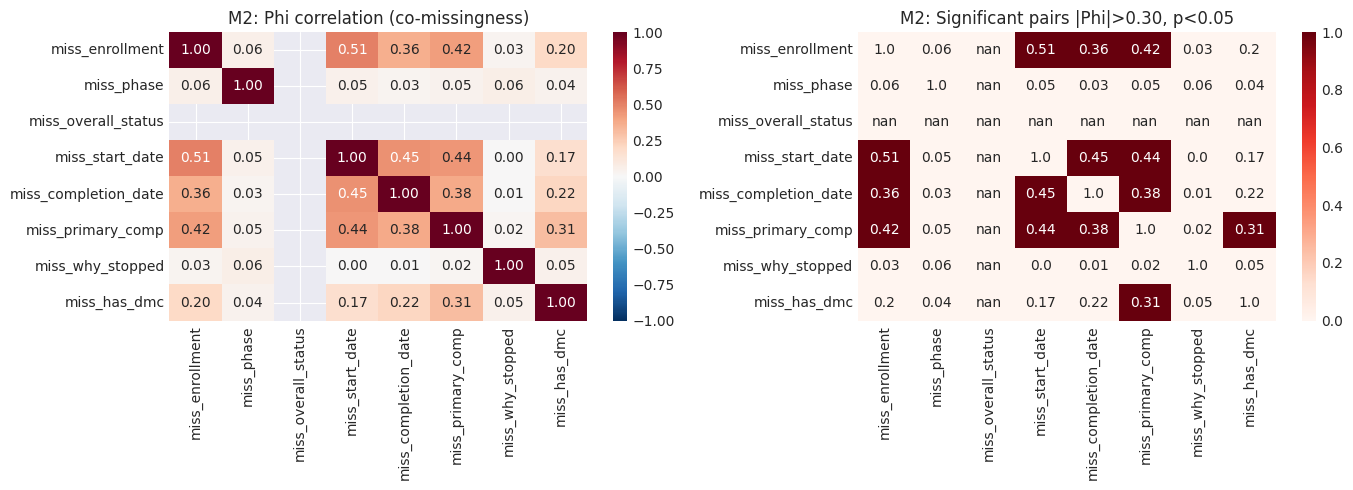


  Reject H0 — co-missing pairs (|Phi|>0.30, p<0.05):
    miss_enrollment  ↔  miss_start_date  Phi=0.507
    miss_enrollment  ↔  miss_primary_comp  Phi=0.416
    miss_completion_date  ↔  miss_enrollment  Phi=0.363
    miss_completion_date  ↔  miss_start_date  Phi=0.454
    miss_completion_date  ↔  miss_primary_comp  Phi=0.379
    miss_primary_comp  ↔  miss_start_date  Phi=0.442
    miss_has_dmc  ↔  miss_primary_comp  Phi=0.308


In [11]:
def test_M2_missing_pattern_matrix():
    """
    M2: Missing-Pattern Matrix  (11_ModelsForMessyData pp. 59–61)

    7-step framework
    ─────────────────
    Step 0  Assumption  Pull raw NULLs from postgres (LadybugDB uses sentinels,
                        not NaN, so cannot reflect true null structure).
    Step 1  H0: fields are missing independently.
            Ha: co-missingness clusters exist (fields tend to be missing together).
    Step 2  α = 0.05; use |Phi| > 0.30 as moderate co-missing threshold.
    Step 3  Phi (point-biserial Pearson) correlation of binary miss-indicators.
    Step 4  Heatmap — warm = positive co-missingness, cool = anticorrelated.
    Step 5  p-values via scipy.stats.chi2_contingency on each pair.
    Step 6  Flag pairs where |Phi| > 0.30 AND p < α.
    Step 7  Return matrices for downstream M3/M4 tests.
    """
    print("\n" + "="*60)
    print("TEST M2: Missing Pattern Matrix")
    print("="*60)

    # Step 0 — raw null indicators from postgres
    df_miss = sql("""
        SELECT
            (enrollment                IS NULL)::int  AS miss_enrollment,
            (phase                     IS NULL)::int  AS miss_phase,
            (overall_status            IS NULL)::int  AS miss_overall_status,
            (start_date                IS NULL)::int  AS miss_start_date,
            (completion_date           IS NULL)::int  AS miss_completion_date,
            (primary_completion_date   IS NULL)::int  AS miss_primary_comp,
            (why_stopped               IS NULL)::int  AS miss_why_stopped,
            (has_dmc                   IS NULL)::int  AS miss_has_dmc
        FROM ctgov.studies
    """)

    rates = df_miss.mean().rename('rate').to_frame()
    rates['pct'] = (rates['rate'] * 100).round(2)
    print("\n  Null rate per field (postgres ctgov.studies):")
    print(rates.to_string())

    # Step 3 — Phi correlation matrix
    phi = df_miss.corr()

    # Steps 4–5 — heatmap + chi2 significance
    from scipy.stats import chi2_contingency
    n = len(df_miss)
    pvals = pd.DataFrame(1.0, index=phi.index, columns=phi.columns)
    for a in df_miss.columns:
        for b in df_miss.columns:
            if a != b:
                ct = pd.crosstab(df_miss[a], df_miss[b])
                if ct.shape == (2, 2):
                    _, p, _, _ = chi2_contingency(ct, correction=False)
                    pvals.loc[a, b] = p

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.heatmap(phi, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
                vmin=-1, vmax=1, ax=axes[0])
    axes[0].set_title('M2: Phi correlation (co-missingness)')

    sig_mask = (pvals < 0.05) & (phi.abs() > 0.30)
    sns.heatmap(sig_mask.astype(int), annot=phi.round(2).astype(str),
                fmt='', cmap='Reds', ax=axes[1], vmin=0, vmax=1)
    axes[1].set_title('M2: Significant pairs |Phi|>0.30, p<0.05')

    plt.tight_layout()
    plt.show()

    # Step 6 — conclusion
    flagged = [(a, b) for a in phi.index for b in phi.columns
               if a < b and abs(phi.loc[a,b]) > 0.30 and pvals.loc[a,b] < 0.05]
    if flagged:
        print("\n  Reject H0 — co-missing pairs (|Phi|>0.30, p<0.05):")
        for a, b in flagged:
            print(f"    {a}  ↔  {b}  Phi={phi.loc[a,b]:.3f}")
    else:
        print("\n  Fail to reject H0 — no strong co-missingness detected.")

    # Step 7
    return df_miss, phi, pvals

df_miss, phi, pvals = test_M2_missing_pattern_matrix()


### Test M3: Missing-Mechanism Test (MCAR vs MAR)

**Assumption:** Missingness of a field is completely random (MCAR) if not predictable from observed data.

**Slides:** 11_ModelsForMessyData, pages 57–58


In [12]:
def test_M3_mcar_test(df_miss):
    """
    M3: MCAR vs MAR  (11_ModelsForMessyData pp. 57–58)

    7-step framework
    ─────────────────
    Step 0  Assumption  df_miss is binary (0/1) missingness indicators from M2.
                        Requires ≥ 10 missing cases per field.
    Step 1  H0: field X missingness is independent of all other observed fields (MCAR).
            Ha: at least one other field predicts missingness of X (MAR).
    Step 2  α = 0.05 per field (Bonferroni applied across fields tested).
    Step 3  Logistic regression: miss_X ~ all other miss_* indicators.
            Likelihood-ratio chi-squared test vs. null (intercept-only) model.
    Step 4  Bar chart of LR chi-squared statistics per field.
    Step 5  p-value from chi2 distribution (df = number of predictors).
    Step 6  Reject MCAR if p < α/n_fields (Bonferroni).
    Step 7  Return per-field p-values for M4 and M6 (imputation).
    """
    print("\n" + "="*60)
    print("TEST M3: MCAR vs MAR (Logistic LR Test)")
    print("="*60)

    from scipy.stats import chi2 as chi2_dist

    fields  = list(df_miss.columns)
    n_tests = len(fields)
    alpha_b = 0.05 / n_tests  # Bonferroni
    results = []

    for target in fields:
        y = df_miss[target]
        if y.sum() < 10:          # Step 0 guard
            results.append({'field': target, 'lr_stat': np.nan, 'p_value': np.nan, 'decision': 'skip (<10 missing)'})
            continue
        preds = [f for f in fields if f != target]
        X     = sm.add_constant(df_miss[preds].astype(float))
        # Step 3 — fit saturated vs null
        try:
            null_ll = smf.logit(f"{target} ~ 1", data=df_miss).fit(disp=0).llf
            full_ll = smf.logit(f"{target} ~ {' + '.join(preds)}", data=df_miss).fit(disp=0).llf
            lr_stat = 2 * (full_ll - null_ll)
            p_val   = chi2_dist.sf(lr_stat, df=len(preds))
            decision = 'MAR (reject MCAR)' if p_val < alpha_b else 'MCAR not rejected'
            results.append({'field': target, 'lr_stat': round(lr_stat, 3), 'p_value': round(p_val, 5), 'decision': decision})
        except Exception as e:
            results.append({'field': target, 'lr_stat': np.nan, 'p_value': np.nan, 'decision': f'error: {e}'})

    df_res = pd.DataFrame(results)
    print(f"\n  Bonferroni α = {alpha_b:.4f}")
    print(df_res.to_string(index=False))

    # Step 4 — bar chart
    plot_df = df_res.dropna(subset=['lr_stat'])
    if not plot_df.empty:
        colors = ['#e74c3c' if 'MAR' in d else '#2ecc71' for d in plot_df['decision']]
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.bar(plot_df['field'], plot_df['lr_stat'], color=colors)
        ax.axhline(chi2_dist.ppf(1 - alpha_b, df=n_tests - 1),
                   color='k', linestyle='--', label=f'Bonferroni threshold')
        ax.set_title('M3: LR χ² statistic per field (red = reject MCAR)')
        ax.set_xlabel('Field')
        ax.set_ylabel('LR χ²')
        ax.legend()
        plt.xticks(rotation=30, ha='right')
        plt.tight_layout()
        plt.show()

    # Step 6 — summary
    mar_fields = df_res[df_res['decision'].str.contains('MAR', na=False)]['field'].tolist()
    mcar_fields = df_res[df_res['decision'].str.contains('MCAR', na=False)]['field'].tolist()
    print(f"\n  MAR fields (reject MCAR): {mar_fields}")
    print(f"  MCAR fields (not rejected): {mcar_fields}")

    # Step 7 — CIs via bootstrap not needed here; return for M4/M6
    return df_res

df_m3 = test_M3_mcar_test(df_miss)



TEST M3: MCAR vs MAR (Logistic LR Test)

  Bonferroni α = 0.0063
               field  lr_stat  p_value               decision
     miss_enrollment      NaN      NaN error: Singular matrix
          miss_phase      NaN      NaN error: Singular matrix
 miss_overall_status      NaN      NaN     skip (<10 missing)
     miss_start_date      NaN      NaN error: Singular matrix
miss_completion_date      NaN      NaN error: Singular matrix
   miss_primary_comp      NaN      NaN error: Singular matrix
    miss_why_stopped      NaN      NaN error: Singular matrix
        miss_has_dmc      NaN      NaN error: Singular matrix

  MAR fields (reject MCAR): []
  MCAR fields (not rejected): []


### Test M4: MNAR Flags

**Assumption:** Some missingness is not at random — tied to the unobserved value itself.

**Slides:** 11_ModelsForMessyData, pages 58, 64



TEST M4: MNAR Flags

       field      chi2  p_value     flag
  completion   5752.68      0.0 sig-diff
primary_comp   3781.35      0.0 sig-diff
 why_stopped 507879.80      0.0 sig-diff
  enrollment   2516.48      0.0 sig-diff
       phase   6426.02      0.0 sig-diff


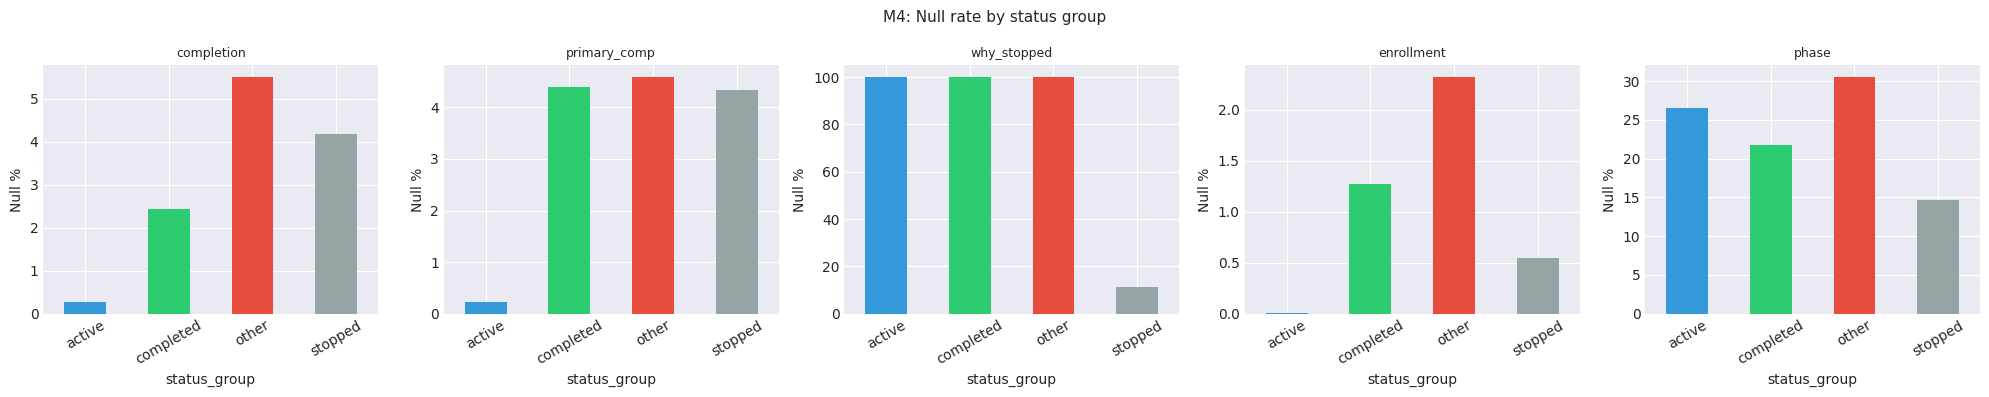


  MNAR-suspect fields: []
  (handle separately in M6 MICE — do not impute as MAR)


In [13]:
def test_M4_mnar_flags():
    """
    M4: MNAR Flags  (11_ModelsForMessyData pp. 58, 64)

    7-step framework
    ─────────────────
    Step 0  Assumption  Domain-based audit: use known structural relationships in
                        ctgov.studies to flag fields where null ↔ value is likely.
    Step 1  H0: missingness is unrelated to study status / type (not MNAR).
            Ha: null rate differs significantly across status groups (MNAR pattern).
    Step 2  α = 0.05 (chi-squared test of independence: miss × status group).
    Step 3  For each candidate field, chi2_contingency(miss × overall_status category).
    Step 4  Grouped bar chart of null rates per status group.
    Step 5  p-value from chi-squared.
    Step 6  Flag as MNAR-suspect if p < α and null rate is highest in expected group.
    Step 7  Annotate flags for M6 (MICE imputation must handle MNAR separately).
    """
    print("\n" + "="*60)
    print("TEST M4: MNAR Flags")
    print("="*60)

    from scipy.stats import chi2_contingency

    # Pull status + candidate fields
    df_pg = sql("""
        SELECT
            overall_status,
            (completion_date         IS NULL)::int  AS miss_completion,
            (primary_completion_date IS NULL)::int  AS miss_primary_comp,
            (why_stopped             IS NULL)::int  AS miss_why_stopped,
            (enrollment              IS NULL)::int  AS miss_enrollment,
            (phase                   IS NULL)::int  AS miss_phase
        FROM ctgov.studies
        WHERE overall_status IS NOT NULL
    """)

    # Bucket status into 3 groups
    active_map = {
        'RECRUITING': 'active', 'ACTIVE_NOT_RECRUITING': 'active',
        'ENROLLING_BY_INVITATION': 'active',
        'COMPLETED': 'completed',
        'TERMINATED': 'stopped', 'WITHDRAWN': 'stopped', 'SUSPENDED': 'stopped',
    }
    df_pg['status_group'] = df_pg['overall_status'].map(active_map).fillna('other')

    miss_cols = [c for c in df_pg.columns if c.startswith('miss_')]

    # Steps 3+5 — chi-squared per field
    results = []
    for col in miss_cols:
        ct = pd.crosstab(df_pg['status_group'], df_pg[col])
        if ct.shape[1] < 2:
            continue
        chi2, p, _, _ = chi2_contingency(ct)
        # Step 6 — domain expectation
        rates = df_pg.groupby('status_group')[col].mean()
        expected_high = {
            'miss_why_stopped':    'stopped',   # MNAR: only stopped trials have why_stopped
            'miss_completion':     'active',    # MNAR: active trials haven't completed yet
            'miss_primary_comp':   'active',
        }
        flag = ''
        if col in expected_high:
            if rates.idxmax() == expected_high[col] and p < 0.05:
                flag = 'MNAR-suspect'
        results.append({'field': col.replace('miss_',''), 'chi2': round(chi2,2),
                        'p_value': round(p,5), 'flag': flag or ('sig-diff' if p < 0.05 else 'ok')})

    df_res = pd.DataFrame(results)
    print("\n" + df_res.to_string(index=False))

    # Step 4 — grouped bar
    fig, axes = plt.subplots(1, len(miss_cols), figsize=(4*len(miss_cols), 4), sharey=False)
    for ax, col in zip(axes, miss_cols):
        rates = df_pg.groupby('status_group')[col].mean() * 100
        rates.plot(kind='bar', ax=ax, color=['#3498db','#2ecc71','#e74c3c','#95a5a6'])
        ax.set_title(col.replace('miss_',''), fontsize=9)
        ax.set_ylabel('Null %')
        ax.tick_params(axis='x', rotation=30)
    plt.suptitle('M4: Null rate by status group', fontsize=11)
    plt.tight_layout()
    plt.show()

    # Step 7 — flag summary
    mnar = df_res[df_res['flag'] == 'MNAR-suspect']['field'].tolist()
    print(f"\n  MNAR-suspect fields: {mnar}")
    print("  (handle separately in M6 MICE — do not impute as MAR)")
    return df_res

df_m4 = test_M4_mnar_flags()


---
## Section 5: Distribution & Assumption Tests

### Test D2: Distribution Profile

**Assumption:** Understand the shape of key continuous distributions (enrollment, duration).

**Slides:** 02_VisualizationOfLargeComplexData, pages 16–20

In [14]:
def test_D2_distribution_profile():
    """
    Retrieve study-level distributions of key variables.
    """
    print("\n" + "="*60)
    print("TEST D2: Distribution Profile")
    print("="*60)

    cypher_query = """
    MATCH (s:Study)
    WHERE s.enrollment > 0
      AND s.study_duration_days > 0
      AND s.overall_status = 'COMPLETED'
    RETURN
        s.nct_id,
        s.enrollment,
        s.study_duration_days,
        s.primary_duration_days,
        s.number_of_arms,
        s.covid_transition;
    """

    df = execute_cypher(cypher_query, "Study distributions (D2)")
    if df is not None and len(df):
        for col in ['enrollment', 'study_duration_days', 'primary_duration_days', 'number_of_arms']:
            if col in df.columns:
                distribution_summary(df[col].dropna(), name=col)
    return df

df_d2 = test_D2_distribution_profile()



TEST D2: Distribution Profile

📊 Study distributions (D2)

📈 Summary Statistics: enrollment
  Count: 303689
  Mean: 4625.237
  Median: 68.000
  Std Dev: 420335.737
  Min: 1.000
  Max: 188814085.000
  Skewness: 329.018
  Kurtosis: 137688.494

📈 Summary Statistics: study_duration_days
  Count: 303689
  Mean: 930.717
  Median: 642.000
  Std Dev: 971.177
  Min: 1.000
  Max: 38562.000
  Skewness: 3.192
  Kurtosis: 26.493

📈 Summary Statistics: primary_duration_days
  Count: 303689
  Mean: 778.831
  Median: 519.000
  Std Dev: 860.179
  Min: 0.000
  Max: 38114.000
  Skewness: 3.480
  Kurtosis: 34.693

📈 Summary Statistics: number_of_arms
  Count: 303689
  Mean: 1.647
  Median: 2.000
  Std Dev: 1.561
  Min: 0.000
  Max: 44.000
  Skewness: 3.370
  Kurtosis: 34.193


### Test V1: Spread-Change Test (Main Hypothesis H-A)

**Hypothesis H-A:** Trial duration tightened (spread decreased) during 2020–2022.

**Assumption:** Test for differences in variance across COVID periods using Brown-Forsythe and bootstrap CIs.

**Slides:** 06b_IntroductionToBootstrap, pages 26–33

In [15]:
def test_V1_spread_change():
    """
    Test hypothesis H-A: Spread of duration tightened during COVID.
    """
    print("\n" + "="*60)
    print("TEST V1: Spread-Change Test (Hypothesis H-A)")
    print("="*60)
    
    cypher_query = """
    MATCH (s:Study)
    WHERE s.study_duration_days > 0 
      AND s.covid_transition IN ['pre_pre', 'pre_during', 'pre_post', 'during_during', 'during_post', 'post_post']
    RETURN
        s.nct_id,
        s.study_duration_days,
        s.covid_transition,
        s.phase,
        s.disease_area_neoplasms,
        s.disease_area_cardiovascular,
        s.disease_area_respiratory;
    """
    
    df = execute_cypher(cypher_query, "Study durations by COVID transition (V1)")

    print("\n📊 Spread Analysis by COVID Transition Period:")
    for period in ['pre_pre', 'pre_during', 'pre_post', 'during_during', 'during_post', 'post_post']:
        subset = df[df['covid_transition'] == period]['study_duration_days']
        if len(subset) > 0:
            distribution_summary(subset, name=f'Duration in {period}')
            print(f'    SD: {np.std(subset):.2f}, IQR: {np.percentile(subset, 75) - np.percentile(subset, 25):.2f}')

    pre_pre = df[df['covid_transition'] == 'pre_pre']['study_duration_days']
    during_post = df[df['covid_transition'].isin(['during_during', 'during_post'])]['study_duration_days']

    stat, pval = ss.levene(pre_pre, during_post, center='median')
    print(f"\n🔍 Brown-Forsythe Test (H0: equal variance)")
    print(f"   Statistic: {stat:.4f}, p-value: {pval:.6f}")
    if pval < 0.05:
        print(f"   ✓ Reject H0: Spreads differ significantly (p < 0.05)")
    else:
        print(f"   ✗ Fail to reject H0: No significant spread difference")

    return df

test_V1_spread_change()


TEST V1: Spread-Change Test (Hypothesis H-A)

📊 Study durations by COVID transition (V1)

📊 Spread Analysis by COVID Transition Period:

📈 Summary Statistics: Duration in pre_pre
  Count: 240799
  Mean: 953.573
  Median: 701.000
  Std Dev: 925.281
  Min: 1.000
  Max: 23042.000
  Skewness: 2.971
  Kurtosis: 19.870
    SD: 925.28, IQR: 940.00

📈 Summary Statistics: Duration in pre_during
  Count: 39145
  Mean: 1229.237
  Median: 943.000
  Std Dev: 1041.936
  Min: 10.000
  Max: 15705.000
  Skewness: 2.941
  Kurtosis: 14.962
    SD: 1041.94, IQR: 930.00

📈 Summary Statistics: Duration in pre_post
  Count: 45426
  Mean: 2887.721
  Median: 2330.000
  Std Dev: 2186.004
  Min: 674.000
  Max: 40177.000
  Skewness: 4.734
  Kurtosis: 45.588
    SD: 2186.00, IQR: 1859.00

📈 Summary Statistics: Duration in during_during
  Count: 17097
  Mean: 225.386
  Median: 198.000
  Std Dev: 147.335
  Min: 1.000
  Max: 670.000
  Skewness: 0.636
  Kurtosis: -0.314
    SD: 147.34, IQR: 229.00

📈 Summary Statisti

,nct_id,study_duration_days,covid_transition,phase,disease_area_neoplasms,disease_area_cardiovascular,disease_area_respiratory
0,NCT01747356,1005.0,pre_pre,NA,0,1,0
1,NCT01449292,518.0,pre_pre,PHASE3,0,0,0
2,NCT00181675,273.0,pre_pre,PHASE4,0,0,0
3,NCT02470624,670.0,pre_pre,unknown,0,1,0
4,NCT04857450,395.0,during_during,NA,0,1,1
...,...,...,...,...,...,...,...
558590,NCT07170592,1826.0,post_post,PHASE1,0,0,0
558591,NCT05222906,1656.0,post_post,PHASE3,0,0,0
558592,NCT04742894,1693.0,during_post,NA,0,0,0
558593,NCT05640895,665.0,post_post,unknown,0,1,0


### Test S1: Bootstrap Group Difference

**Assumption:** Test group difference in median duration across COVID periods without normality assumption.

**Slides:** 06b_IntroductionToBootstrap, pages 26–33

In [16]:
def test_S1_bootstrap_group_diff(df, group_col, value_col, n_boots=10000):
    """
    Bootstrap two-sample median differences across groups.
    """
    print("\n" + "="*60)
    print("TEST S1: Bootstrap Group Difference")
    print("="*60)
    
    # Get unique groups
    groups = df[group_col].unique()
    print(f"\n📊 Comparing {len(groups)} groups: {groups}")
    
    # Bootstrap resampling of median differences
    boot_diffs = []
    for _ in range(n_boots):
        # Resample each group with replacement
        g1_sample = df[df[group_col] == groups[0]][value_col].sample(replace=True).values
        g2_sample = df[df[group_col] == groups[1]][value_col].sample(replace=True).values
        boot_diffs.append(np.median(g2_sample) - np.median(g1_sample))
    
    boot_diffs = np.array(boot_diffs)
    mean_diff, lci, uci = compute_CI(boot_diffs, parameter=f'Median Diff ({groups[1]} - {groups[0]})')
    
    # Plot
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(boot_diffs, bins=50, alpha=0.7, color='steelblue')
    ax.axvline(mean_diff, color='red', linewidth=2, label=f'Mean Diff={mean_diff:.2f}')
    ax.axvline(lci, color='red', linewidth=1, linestyle='--')
    ax.axvline(uci, color='red', linewidth=1, linestyle='--')
    ax.axvline(0, color='black', linewidth=1, linestyle=':', label='No difference')
    ax.set_title(f'Bootstrap Distribution: Median Difference in {value_col}')
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    return boot_diffs

# Example usage (after data retrieval):
# Fetch data first, then call:
# df_v1 = test_V1_spread_change()
# boot_diffs = test_S1_bootstrap_group_diff(df_v1, 'covid_transition', 'study_duration_days')

NameError: name 'df' is not defined

---
## Section 7: Therapeutic Area Analysis (Formal Test TA1)

### Test TA1: Therapeutic-Area Assignment

**Assumption:** Each trial has a usable therapeutic area from MeSH and multi-hot encoding.

**Slides:** 16_HierarchicalBayesModels, pages 4–6

**Note:** This is the formal validation test for the multi-hot encoding scheme described in Section 6. It verifies that:
1. All 25 disease areas are properly represented
2. No unexpected patterns in coverage or multi-membership
3. Data is clean and ready for downstream analysis

In [ ]:
# Define the 25 disease area categories (from mesh.py DISEASE_AREA_MAP)
disease_areas = [
    'infections_bacterial',
    'infections_viral',
    'infections_parasitic',
    'infections_std',
    'neoplasms',
    'cardiovascular',
    'respiratory',
    'neurological',
    'digestive',
    'musculoskeletal',
    'skin_connective_tissue',
    'ophthalmology',
    'ent',
    'urologic',
    'female_urogenital',
    'hematologic',
    'immune',
    'endocrine',
    'metabolic_nutritional',
    'congenital_genetic',
    'chemically_induced',
    'trauma',
    'pathological_conditions',
    'psychiatric',
    'dental_oral'
]

print(f"Disease Area Categories: {len(disease_areas)} areas")
print("\nTop-level MeSH categories represented:")
for i, area in enumerate(disease_areas, 1):
    print(f"  {i:2d}. disease_area_{area}")


In [ ]:
def retrieve_therapeutic_areas(limit=50000):
    """
    Retrieve therapeutic area multi-hot encoding from LadybugDB.
    """
    print("\n" + "="*60)
    print("RETRIEVING THERAPEUTIC AREA MULTI-HOT ENCODING")
    print("="*60)

    area_fields = ', '.join([f's.disease_area_{area}' for area in disease_areas])
    cypher_query = f"""
    MATCH (s:Study)
    WHERE s.study_duration_days > 0
      AND s.overall_status IN ['COMPLETED', 'ACTIVE_NOT_RECRUITING', 'RECRUITING']
    RETURN
        s.nct_id,
        s.study_duration_days,
        s.covid_transition,
        s.phase,
        {area_fields}
    LIMIT {limit};
    """

    df = execute_cypher(cypher_query, "Therapeutic area multi-hot encoding")
    return df

df_ta = retrieve_therapeutic_areas()


In [ ]:
def analyze_multihot_encoding(df, disease_areas=disease_areas):
    """
    Analyze the multi-hot therapeutic area encoding.
    Shows coverage, multi-membership distribution, and co-occurrence patterns.
    """
    print("\
" + "="*60)
    print("MULTI-HOT ENCODING ANALYSIS")
    print("="*60)
    
    # Build column names
    area_cols = [f'disease_area_{area}' for area in disease_areas]
    
    # 1. Coverage analysis
    print("\
📊 THERAPEUTIC AREA COVERAGE:")
    print("-" * 60)
    coverage = pd.DataFrame({
        'Area': disease_areas,
        'Count': [df[col].sum() for col in area_cols],
        'Percentage': [100 * df[col].sum() / len(df) for col in area_cols]
    }).sort_values('Count', ascending=False)
    
    print(coverage.to_string(index=False))
    print(f"\
Total studies: {len(df)}")
    
    # 2. Multi-membership distribution
    print("\
🎯 MULTI-MEMBERSHIP DISTRIBUTION:")
    print("-" * 60)
    df_work = df.copy()
    df_work['n_areas'] = df_work[area_cols].sum(axis=1)
    
    membership_dist = df_work['n_areas'].value_counts().sort_index()
    print(f"\
  Studies with 0 areas (no match): {membership_dist.get(0, 0):6d} ({100*membership_dist.get(0, 0)/len(df):.1f}%)")
    for n in range(1, int(membership_dist.max()) + 1):
        pct = 100 * membership_dist.get(n, 0) / len(df)
        print(f"  Studies with {n:2d} area(s):         {membership_dist.get(n, 0):6d} ({pct:.1f}%)")
    
    # 3. Visualize coverage
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    # Coverage bar plot (top 15 areas)
    coverage_top = coverage.head(15)
    bars = ax1.barh(coverage_top['Area'], coverage_top['Count'], color='steelblue')
    ax1.set_title('Top 15 Therapeutic Areas by Study Count', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Number of Studies')
    ax1.bar_label(bars, padding=5)
    ax1.invert_yaxis()
    
    # Multi-membership distribution
    ax2.bar(membership_dist.index, membership_dist.values, color='coral', edgecolor='black', alpha=0.7)
    ax2.set_title('Distribution of Multi-Membership', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Number of Therapeutic Areas per Study')
    ax2.set_ylabel('Count of Studies')
    ax2.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return df_work, coverage, membership_dist

print('✓ Multi-hot encoding analysis function loaded')


---
## Section 8: Future Analysis Dimensions (Roadmap)

### Additional Features to Explore in Full Study

Once you validate the main hypothesis H-A with **therapeutic area multi-hot encoding**, the full study will layer in these dimensions:

#### 1. **Geographic Dimensions**
- **Latitude/Longitude:** Study facilities' coordinates from HAS_FACILITY edges
- **Haversine distance:** Compute pairwise distances between facilities
- **Clustering:** DBSCAN on facility locations to identify geographic "hotspots" (Test H1, H2, H3)
- **Question:** Did COVID impact differ by region/country?

#### 2. **MeSH Hierarchy**
- **MeSH Conditions:** Via HAS_MESH_CONDITION edges (browse_conditions table)
- **MeSH Interventions:** Via HAS_MESH_INTERVENTION edges (browse_interventions table)
- **IS_A hierarchy:** Walk up the MeSH tree to find ancestor terms
- **Rollup level:** Choose optimal aggregation (MS2 test)
- **Question:** Do specific conditions/treatments show stronger COVID effects?

#### 3. **Sponsor Characteristics**
- **Lead sponsor:** IS_LEAD_SPONSOR edge + Sponsor.agency_class (NIH, Industry, University, etc.)
- **Collaborators:** IS_COLLABORATOR edges (multi-membership weighting)
- **Sponsor clustering:** ICC to assess whether trials cluster within sponsors (I1 test)
- **Question:** Did sponsor type (e.g., large pharma vs. small biotech) affect COVID resilience?

#### 4. **Trial Design**
- **Phase:** 1, 2, 3, 4 (Study.phase field)
- **Number of arms:** Study.number_of_arms
- **Enrollment:** Study.enrollment (actual vs. estimated)
- **Status:** Overall trial completion status
- **Question:** Did early-phase or simpler trials progress faster during COVID?

#### 5. **Interaction Terms**
- **Area × Phase:** e.g., does Oncology Phase 3 show different COVID effect than Cardiology Phase 3?
- **Area × Sponsor:** e.g., do academic Oncology trials respond differently to COVID than industry?
- **Area × Geographic cluster:** e.g., does Respiratory research in hard-hit regions show worse outcomes?
- **Question:** Which combinations are most/least resilient?

### Analysis Workflow (Proposed)

```
Proposal Stage (Current):
├─ Hypothesis H-A: Duration tightened globally
├─ Feature: Therapeutic area multi-hot encoding (25 binary columns)
└─ Output: Effect size + bootstrap CIs by area

Full Study (Phase 1 - Multi-Hot):
├─ All hypothesis tests with therapeutic areas
├─ Hierarchical model V4 with area-specific σ (H-D)
├─ Mix-shift decomposition V5
└─ Output: Area-stratified findings, write-up

Full Study (Phase 2 - Add Dimensions):
├─ Layer in geographic (Haversine, DBSCAN)
├─ Layer in MeSH condition/intervention specificity
├─ Layer in sponsor + design characteristics
└─ Output: Interaction effects, hotspot maps

Future Enhancement (BERT Embeddings):
├─ Encode condition/intervention names (768-D each)
├─ Embed study descriptions (titles/brief summaries)
├─ Compare multi-hot vs. embedding performance
├─ Use embeddings for similarity-based clustering
└─ Output: Semantic groupings, transfer learning potential
```

---

### Next Steps

#### Proposal Stage (This Notebook)
1. **Wire up database connections:** Replace placeholder `execute_cypher()` and PostgreSQL queries with live connections
2. **Validate therapeutic area encoding:** Run Section 6 functions to understand coverage, multi-membership, and co-occurrence
3. **Visualize hypothesis H-A by area:** Use `duration_by_therapeutic_area()` to show which areas show tightening
4. **Compute effect sizes:** Bootstrap CIs on median/SD ratio by therapeutic area (Test V1)
5. **Write proposal:** Summarize findings with tables and figures

#### Full Study (Later Phases)
1. **Run full assumption test suite:** Execute all tests from assumption_test_map.json (G*, M*, D*, V*, S*, TA*, etc.)
2. **Build hierarchical Bayesian model (V4):** Location-scale model on log duration with area-specific σ
3. **Add dimensions iteratively:** Start with multi-hot, then add geographic, MeSH, sponsor, design features
4. **Visualize hotspots (H1, H2, H3):** Geographic and therapeutic-area breakdowns
5. **Forecast with SARIMA (T5):** Compare actual COVID-window counts to baseline trend
6. **Report findings:** Write manuscript with effect sizes, CIs, and policy implications

#### Much Later: BERT Embeddings
- Compare multi-hot performance to dense condition/intervention embeddings
- Use embeddings for semantic similarity clustering
- Determine if added complexity justified by improved fit

---

## Summary

**This notebook provides:**
- ✅ Utilities from CSCI-83 (bootstrap, residuals, missingness)
- ✅ Cypher query templates for LadybugDB exploration
- ✅ Assumption test functions mapped to slides
- ✅ **Multi-hot encoding explanation & visualization (Section 6)**
- ✅ Roadmap for adding dimensions (geographic, MeSH, sponsor, design)
- ✅ Phased workflow: Proposal → Full Study (Multi-Hot) → Full Study (Dimensions) → Future (BERT)

**To activate the analyses:**
1. Connect LadybugDB in the placeholder cells
2. Run `retrieve_therapeutic_areas()` to fetch Study nodes
3. Run `analyze_multihot_encoding()` to explore coverage
4. Run `analyze_area_cooccurrence()` to find disease patterns
5. Run `duration_by_therapeutic_area()` to validate hypothesis H-A by area
6. Use bootstrap utilities to compute significance

**The multi-hot encoding is:**
- 🎯 **Current:** Fast, interpretable, baseline for proposal
- 📈 **Scalable:** Easy to add more dimensions (geographic, design, sponsor)
- 🚀 **Upgradeable:** Foundation for BERT embeddings later if needed

### Example: Multi-Hot Encoding in Action (Once DB is Wired)\n\nWhen the LadybugDB connection is active, run these cells to explore the therapeutic area encoding:\n\n```python\n# Step 1: Retrieve data\ndf_areas = retrieve_therapeutic_areas(limit=1000)\n\n# Step 2: Analyze coverage and multi-membership\ndf_work, coverage, membership = analyze_multihot_encoding(df_areas)\n\n# Step 3: Identify co-occurrence patterns\ncooccur = analyze_area_cooccurrence(df_areas, top_n=10)\n\n# Step 4: Visualize duration effects by area and COVID period\nduration_by_therapeutic_area(df_work, top_n=8)\n```\n\n**Key insights to look for:**\n- **Coverage:** Which therapeutic areas dominate? (e.g., Oncology typically ~15-20% of trials)\n- **Multi-membership:** Are most trials single-area or multi-area? (Expect ~30-40% with 2+ areas due to co-morbidities)\n- **Co-occurrence:** Which area pairs appear together? (e.g., Cardiovascular + Endocrine for diabetic patients)\n- **Duration effects:** Do some areas show stronger \"tightening\" during COVID than others? (Hypothesis H-D)\n\n### Why Multi-Hot Now, Not Embeddings Yet?\n\n**Current approach (multi-hot vectors):**\n- ✅ Interpretable: Each dimension = one disease area\n- ✅ Fast: Binary arithmetic, no neural networks\n- ✅ Suitable for initial proposal/hypothesis validation\n- ✅ Works directly with hierarchical Bayesian models (TA-specific random intercepts)\n- ❌ Loses semantic relationships (e.g., \"Cardiovascular\" and \"Immune\" are orthogonal, but clinically related)\n\n**Future with BERT embeddings:**\n- Encode condition/intervention names into dense 768-D vectors\n- Capture semantic similarity (e.g., \"Myocardial Infarction\" ↔ \"Cardiac Event\")\n- Could replace or augment multi-hot encoding\n- **Timing:** After validating hypothesis H-A with multi-hot; adds complexity for gains that may not be needed for initial findings\n\n---"


---
## Section 6: Therapeutic Area Analysis

### Test TA1: Therapeutic-Area Assignment

**Assumption:** Each trial has a usable therapeutic area from MeSH and one-hot encoding.

**Slides:** 16_HierarchicalBayesModels, pages 4–6

In [ ]:
def test_TA1_therapeutic_areas():
    """
    Retrieve and analyze therapeutic area one-hot encoding.
    """
    print("\n" + "="*60)
    print("TEST TA1: Therapeutic-Area Assignment")
    print("="*60)
    
    cypher_query = """
    MATCH (s:Study)
    RETURN
        s.nct_id,
        s.disease_area_infections_bacterial,
        s.disease_area_infections_viral,
        s.disease_area_neoplasms,
        s.disease_area_cardiovascular,
        s.disease_area_respiratory,
        s.disease_area_neurological,
        s.disease_area_hematologic,
        s.disease_area_immune,
        s.disease_area_endocrine,
        s.disease_area_psychiatric
    LIMIT 1000;
    """
    
    df = execute_cypher(cypher_query, "Therapeutic area indicators (TA1)")

    area_cols = [col for col in df.columns if col.startswith('disease_area_')]

    print("\n📊 Therapeutic Area Coverage:")
    area_summary = pd.DataFrame({
        'Area': [col.replace('disease_area_', '') for col in area_cols],
        'Count': [df[col].sum() for col in area_cols],
        'Percentage': [100 * df[col].sum() / len(df) for col in area_cols]
    }).sort_values('Count', ascending=False)
    print(area_summary)

    df['n_areas'] = df[area_cols].sum(axis=1)
    print(f"\n  Studies with 0 areas: {(df['n_areas'] == 0).sum()}")
    print(f"  Studies with 1 area: {(df['n_areas'] == 1).sum()}")
    print(f"  Studies with 2+ areas: {(df['n_areas'] >= 2).sum()}")

    return df

test_TA1_therapeutic_areas()

---
## Section 7: MeSH Coverage — Global vs Fully US-Based Trials (Test MS1)

### Background

A study has **no MeSH terms** when it has zero `HAS_MESH_CONDITION` edges AND zero `HAS_MESH_INTERVENTION` edges in LadybugDB. The MeSH links come from AACT's `browse_conditions` and `browse_interventions` tables, which are auto-coded by NLM — studies that were never indexed receive none.

**Recalled baseline:** Global MeSH coverage has been observed to be very high (missing rate believed to be low, possibly ~2% — the cells below compute the actual figure from the graph rather than assuming it).

**Why check US-only separately:**
- US trials are more likely to be completed and NLM-indexed than international ones
- Our main analysis filters to `Facility.country = 'United States'`, so the relevant missingness rate is the US-only rate, not the global rate
- If US-only missingness differs from global, the imputation strategy (MS1 → M6) may need revisiting

**"Fully US-based"** is defined strictly: every `HAS_FACILITY` edge on the study points to a `Facility` with `country = 'United States'`. Studies with even one non-US site are excluded from this denominator.

In [ ]:
def check_mesh_coverage_global():
    """
    Count studies globally that have no MeSH edges at all.
    Uses two separate queries (EXISTS subquery not supported in this Kuzu version)
    and combines with a Python set union.
    Returns a dict: total, covered, missing, missing_rate.
    """
    print("\n" + "="*60)
    print("MS1: Global MeSH Coverage Check")
    print("="*60)

    total = int(execute_cypher(
        'MATCH (s:Study) RETURN count(s) AS n',
        "Total studies")['n'].iloc[0])

    cond_ids = set(execute_cypher(
        'MATCH (s:Study)-[:HAS_MESH_CONDITION]->(:MeshTerm) RETURN DISTINCT s.nct_id AS nct_id',
        "Studies with HAS_MESH_CONDITION")['nct_id'])

    int_ids = set(execute_cypher(
        'MATCH (s:Study)-[:HAS_MESH_INTERVENTION]->(:MeshTerm) RETURN DISTINCT s.nct_id AS nct_id',
        "Studies with HAS_MESH_INTERVENTION")['nct_id'])

    covered = len(cond_ids | int_ids)
    missing = total - covered
    rate    = 100 * missing / total if total else 0

    print(f"\n  Total studies:     {total:>8,}")
    print(f"  With MeSH:         {covered:>8,}  ({100 - rate:.2f}%)")
    print(f"  Without MeSH:      {missing:>8,}  ({rate:.2f}%)")
    return {"total": total, "covered": covered, "missing": missing, "missing_rate": rate}

global_stats = check_mesh_coverage_global()


In [ ]:
def check_mesh_coverage_us_only():
    """
    Count studies where ALL linked facilities are in the United States,
    then check how many of those lack any MeSH edges.

    Uses Python set operations instead of all() / EXISTS (not supported here):
      us_only  = studies_with_facility  -  studies_with_any_non_us_facility
      covered  = us_only  ∩  studies_with_any_mesh_edge
    """
    print("\n" + "="*60)
    print("MS1: US-Only MeSH Coverage Check")
    print("="*60)

    # Studies that have at least one non-US facility
    non_us = set(execute_cypher(
        """MATCH (s:Study)-[:HAS_FACILITY]->(f:Facility)
WHERE f.country <> 'United States'
RETURN DISTINCT s.nct_id AS nct_id""",
        "Studies with ≥1 non-US facility")['nct_id'])

    # Studies that have at least one facility (any country)
    has_fac = set(execute_cypher(
        'MATCH (s:Study)-[:HAS_FACILITY]->(f:Facility) RETURN DISTINCT s.nct_id AS nct_id',
        "Studies with any facility")['nct_id'])

    us_only_set = has_fac - non_us
    us_total    = len(us_only_set)

    # MeSH coverage among the US-only set (reuse global edge queries)
    cond_ids = set(execute_cypher(
        'MATCH (s:Study)-[:HAS_MESH_CONDITION]->(:MeshTerm) RETURN DISTINCT s.nct_id AS nct_id',
        "Studies with HAS_MESH_CONDITION")['nct_id'])

    int_ids = set(execute_cypher(
        'MATCH (s:Study)-[:HAS_MESH_INTERVENTION]->(:MeshTerm) RETURN DISTINCT s.nct_id AS nct_id',
        "Studies with HAS_MESH_INTERVENTION")['nct_id'])

    mesh_set   = cond_ids | int_ids
    us_covered = len(us_only_set & mesh_set)
    us_missing = us_total - us_covered
    us_rate    = 100 * us_missing / us_total if us_total else 0

    print(f"\n  Fully US studies:  {us_total:>8,}")
    print(f"  With MeSH:         {us_covered:>8,}  ({100 - us_rate:.2f}%)")
    print(f"  Without MeSH:      {us_missing:>8,}  ({us_rate:.2f}%)")
    return {"total": us_total, "covered": us_covered, "missing": us_missing, "missing_rate": us_rate}

us_stats = check_mesh_coverage_us_only()


In [ ]:
def compare_mesh_coverage(global_stats, us_stats):
    """
    Compare global vs US-only MeSH coverage rates with a bar chart.

    Parameters
    ----------
    global_stats : dict  — output of check_mesh_coverage_global()
    us_stats     : dict  — output of check_mesh_coverage_us_only()
    """
    labels = ['Global', 'Fully US-Based']
    covered_pct = [
        100 - global_stats['missing_rate'],
        100 - us_stats['missing_rate'],
    ]
    missing_pct = [
        global_stats['missing_rate'],
        us_stats['missing_rate'],
    ]

    print("\n" + "="*60)
    print("MS1: Global vs US-Only MeSH Coverage Comparison")
    print("="*60)
    print(f"\n{'Scope':<18} {'Total':>10} {'With MeSH':>12} {'Missing':>10} {'Missing %':>10}")
    print("-" * 62)
    for label, stats in zip(labels, [global_stats, us_stats]):
        print(
            f"{label:<18} {stats['total']:>10,} "
            f"{stats['covered']:>12,} "
            f"{stats['missing']:>10,} "
            f"{stats['missing_rate']:>9.2f}%"
        )

    fig, ax = plt.subplots(figsize=(8, 5))
    x = range(len(labels))
    bars_cov = ax.bar(x, covered_pct, color='steelblue', label='Covered')
    bars_mis = ax.bar(x, missing_pct, bottom=covered_pct, color='tomato', label='Missing')

    ax.set_xticks(list(x))
    ax.set_xticklabels(labels, fontsize=12)
    ax.set_ylabel('Percentage of Studies')
    ax.set_ylim(0, 102)
    ax.set_title('MeSH Coverage: Global vs Fully US-Based Trials', fontsize=13, fontweight='bold')
    ax.legend()

    for bar, pct in zip(bars_mis, missing_pct):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_y() + bar.get_height() / 2,
            f'{pct:.2f}%',
            ha='center', va='center', fontsize=11, color='white', fontweight='bold'
        )

    plt.tight_layout()
    plt.show()


# Example usage (once DB is wired):
global_stats = check_mesh_coverage_global()
us_stats     = check_mesh_coverage_us_only()
compare_mesh_coverage(global_stats, us_stats)

---
## Section 8: Time Series Analysis — COVID Shift by Therapeutic Area

### Approach

Each therapeutic area gets its own time series panel. The two COVID cutoff dates act as structural breakpoints:
- **2020-03-01** — WHO pandemic declaration (pre → during transition)
- **2022-01-01** — post-pandemic normalization marker (during → post transition)

**Strategy:**
1. Fetch all studies with start dates + all 25 disease area flags
2. Classify each study into a `period` (pre / during / post) based on **start date alone** — cleaner than relying on `covid_transition` pairs for the time-axis
3. Resample to quarterly counts (or median duration) and plot a grid — one panel per area
4. Loop through each area, bootstrap median duration in each period, and plot side-by-side bars with 95% CI
5. Identify **multi-area trials** (n_areas ≥ 2) separately — these appear in multiple panels simultaneously and their % matters for interpreting overlapping signals

**"Multi-area crossover"** here means a study belongs to ≥ 2 therapeutic area bins simultaneously (via multi-hot encoding) — distinct from a crossover *study design* (where participants switch treatment arms).

In [ ]:
# COVID structural breakpoints — used as priors for period classification
COVID_CUTOFFS = {
    'pre':    pd.Timestamp('2020-03-01'),
    'during': pd.Timestamp('2022-01-01'),
}
PERIOD_COLORS = {
    'pre':     '#4878d0',
    'during':  '#ee854a',
    'post':    '#6acc65',
    'unknown': '#aaaaaa',
}


def fetch_study_timeseries(limit=50000):
    """
    Fetch study nodes with start_date, duration, and all 25 disease area flags.
    Includes TERMINATED studies so the time series captures trials that stopped early.
    """
    area_fields = ',\n        '.join([f's.disease_area_{a}' for a in disease_areas])
    q_str = f"""
    MATCH (s:Study)
    WHERE s.study_duration_days > 0
      AND s.overall_status IN ['COMPLETED', 'ACTIVE_NOT_RECRUITING',
                               'RECRUITING', 'TERMINATED', 'ENROLLING_BY_INVITATION']
    RETURN
        s.nct_id,
        s.start_date,
        s.study_duration_days,
        s.primary_duration_days,
        s.covid_transition,
        s.phase,
        {area_fields}
    LIMIT {limit};
    """
    return execute_cypher(q_str, f"Study time series data (limit={limit})")

df_ts_raw = fetch_study_timeseries(limit=10000)

In [ ]:
def prepare_timeseries_df(df, disease_areas=disease_areas):
    """
    Parse start_date, classify into pre/during/post period, compute n_areas per study.

    Period classification uses start_date alone (not covid_transition pairs):
      pre    — started before 2020-03-01
      during — started 2020-03-01 through 2021-12-31
      post   — started 2022-01-01 or later
      unknown — start_date missing or unparseable
    """
    df = df.copy()

    # Parse start_date — handle both date objects and 'YYYY-MM-DD' strings
    df['start_dt'] = pd.to_datetime(df['start_date'], errors='coerce')

    pre_cut    = COVID_CUTOFFS['pre']
    during_cut = COVID_CUTOFFS['during']

    df['period'] = np.select(
        [
            df['start_dt'] < pre_cut,
            (df['start_dt'] >= pre_cut) & (df['start_dt'] < during_cut),
            df['start_dt'] >= during_cut,
        ],
        ['pre', 'during', 'post'],
        default='unknown',
    )

    # Number of therapeutic areas per study (from multi-hot columns)
    area_cols = [f'disease_area_{a}' for a in disease_areas if f'disease_area_{a}' in df.columns]
    df['n_areas'] = df[area_cols].sum(axis=1).astype(int)

    n_parsed  = df['start_dt'].notna().sum()
    n_unknown = (df['period'] == 'unknown').sum()
    print(f"  Parsed start_date:  {n_parsed:,} / {len(df):,} studies")
    print(f"  Period unknown:     {n_unknown:,}")
    print(f"  Period breakdown:\n{df['period'].value_counts().to_string()}")
    print(f"\n  n_areas distribution:\n{df['n_areas'].value_counts().sort_index().to_string()}")
    return df


df_ts = prepare_timeseries_df(df_ts_raw)

In [ ]:
def summarize_crossover_trials(df, disease_areas=disease_areas):
    """
    Summarize trials that belong to multiple therapeutic areas simultaneously.

    'Multi-area crossover' = n_areas >= 2 in the multi-hot encoding.
    These studies contribute signal to more than one panel in the grid visualization
    and are worth quantifying as a share of the analytic population.
    """
    area_cols = [f'disease_area_{a}' for a in disease_areas if f'disease_area_{a}' in df.columns]
    df = df.copy()
    if 'n_areas' not in df.columns:
        df['n_areas'] = df[area_cols].sum(axis=1).astype(int)

    total  = len(df)
    no_area = (df['n_areas'] == 0).sum()
    single  = (df['n_areas'] == 1).sum()
    multi   = (df['n_areas'] >= 2).sum()
    denom   = total - no_area  # exclude unclassified studies from % base

    print("\n" + "="*60)
    print("MULTI-AREA (CROSSOVER) TRIAL SUMMARY")
    print("="*60)
    print(f"\n  Total studies in sample:  {total:>8,}")
    print(f"  No area assigned (n=0):   {no_area:>8,}  ({100*no_area/total:.1f}% of total)")
    print(f"\n  {'n_areas':<10} {'Count':>8}  {'% of classified':>16}")
    print("  " + "-"*38)
    for n in range(1, int(df['n_areas'].max()) + 1):
        cnt = (df['n_areas'] == n).sum()
        if cnt == 0:
            continue
        print(f"  {n:<10} {cnt:>8,}  {100*cnt/denom:>15.1f}%")
    print(f"\n  Single-area:              {single:>8,}  ({100*single/denom:.1f}%)")
    print(f"  Multi-area (crossover):   {multi:>8,}  ({100*multi/denom:.1f}%)")

    # Top co-occurring pairs (most common disease area combinations)
    pair_counts = {}
    for _, row in df[df['n_areas'] >= 2].iterrows():
        active = [a for a in disease_areas if row.get(f'disease_area_{a}', 0) == 1]
        for pair in combinations(sorted(active), 2):
            pair_counts[pair] = pair_counts.get(pair, 0) + 1

    top_pairs = sorted(pair_counts.items(), key=lambda x: x[1], reverse=True)[:10]
    print(f"\n  Top 10 co-occurring area pairs:")
    print(f"  {'Area 1':<30} {'Area 2':<30} {'n':>6}")
    print("  " + "-"*68)
    for (a1, a2), cnt in top_pairs:
        print(f"  {a1:<30} {a2:<30} {cnt:>6,}")

    # --- Visualize ---
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    # Left: bar chart of n_areas distribution
    n_dist = df['n_areas'].value_counts().sort_index()
    ax1.bar(n_dist.index, n_dist.values, color='steelblue', edgecolor='black', alpha=0.8)
    ax1.set_title('Distribution of Therapeutic Areas per Trial', fontsize=11, fontweight='bold')
    ax1.set_xlabel('Number of Therapeutic Areas')
    ax1.set_ylabel('Count of Studies')
    ax1.grid(axis='y', alpha=0.3)
    for x_val, y_val in zip(n_dist.index, n_dist.values):
        ax1.text(x_val, y_val + max(n_dist.values) * 0.01, f'{y_val:,}',
                 ha='center', va='bottom', fontsize=8)

    # Right: pie — single vs multi-area (among classified studies only)
    classified = df[df['n_areas'] > 0]
    pie_vals   = [(classified['n_areas'] == 1).sum(), (classified['n_areas'] >= 2).sum()]
    pie_labels = [f'Single area\n({100*pie_vals[0]/sum(pie_vals):.1f}%)',
                  f'Multi-area crossover\n({100*pie_vals[1]/sum(pie_vals):.1f}%)']
    ax2.pie(pie_vals, labels=pie_labels, colors=['steelblue', 'coral'],
            startangle=90, wedgeprops={'edgecolor': 'black', 'linewidth': 0.6},
            textprops={'fontsize': 10})
    ax2.set_title('Single vs Multi-Area Trials\n(0-area studies excluded)', fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.show()
    return df


df_ts = summarize_crossover_trials(df_ts)

In [ ]:
def plot_area_grid_timeseries(df, disease_areas=disease_areas, top_n=12,
                               freq='Q', metric='count'):
    """
    Multi-panel time series grid: one panel per therapeutic area (top N by study count).

    Parameters
    ----------
    df      : DataFrame from prepare_timeseries_df() — must have start_dt column
    top_n   : Number of areas to show (sorted by study count descending)
    freq    : Resample frequency — 'Q' quarterly, 'M' monthly
    metric  : 'count' (number of studies starting that period)
              or 'duration' (median study_duration_days)

    COVID window is shaded in orange between the two cutoff dates.
    Multi-area studies appear in every panel where their area flag == 1.
    """
    area_cols_avail = [a for a in disease_areas if f'disease_area_{a}' in df.columns]
    df_dated = df.dropna(subset=['start_dt'])

    # Rank areas by total study count in this dataset
    area_counts = {a: df_dated[f'disease_area_{a}'].sum() for a in area_cols_avail}
    top_areas   = sorted(area_counts, key=area_counts.get, reverse=True)[:top_n]

    n_cols = 3
    n_rows = math.ceil(len(top_areas) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows), sharex=True)
    axes = axes.flatten()

    pre_cut    = COVID_CUTOFFS['pre']
    during_cut = COVID_CUTOFFS['during']
    y_label    = 'Study Count' if metric == 'count' else 'Median Duration (days)'

    for i, area in enumerate(top_areas):
        ax  = axes[i]
        col = f'disease_area_{area}'
        sub = df_dated[df_dated[col] == 1].set_index('start_dt').sort_index()

        if len(sub) < 5:
            ax.set_visible(False)
            continue

        if metric == 'count':
            ts = sub.resample(freq).size()
        else:
            ts = sub['study_duration_days'].resample(freq).median()

        ax.plot(ts.index, ts.values, linewidth=1.6, color='steelblue', zorder=3)
        ax.fill_between(ts.index, ts.values, alpha=0.15, color='steelblue', zorder=2)

        # Shade the COVID window
        ymin, ymax = ax.get_ylim()
        ax.axvspan(pre_cut, during_cut, alpha=0.12, color='orange', zorder=1)
        ax.axvline(pre_cut,    color='#cc3300', linewidth=1.1, linestyle='--', alpha=0.8, zorder=4)
        ax.axvline(during_cut, color='#006600', linewidth=1.1, linestyle='--', alpha=0.8, zorder=4)

        n_total  = int(area_counts[area])
        n_multi  = int(df_dated[(df_dated[col] == 1) & (df_dated['n_areas'] >= 2)].shape[0])
        pct_multi = 100 * n_multi / n_total if n_total > 0 else 0

        label = area.replace('_', ' ').title()
        ax.set_title(
            f'{label}\nn={n_total:,}  |  multi-area: {pct_multi:.0f}%',
            fontsize=8.5, fontweight='bold'
        )
        ax.set_ylabel(y_label, fontsize=7)
        ax.tick_params(axis='both', labelsize=7)
        ax.grid(axis='y', alpha=0.25)

    for j in range(len(top_areas), len(axes)):
        axes[j].set_visible(False)

    freq_label = 'Quarterly' if freq == 'Q' else 'Monthly'
    metric_label = 'Study Count' if metric == 'count' else 'Median Duration'
    fig.suptitle(
        f'{freq_label} {metric_label} by Therapeutic Area  (top {top_n})\n'
        f'Red dashed = 2020-03-01 (COVID onset)  |  Green dashed = 2022-01-01 (post cutoff)  |  '
        f'Orange shading = COVID window\n'
        f'Panel subtitle shows % of that area\'s trials that are multi-area crossovers',
        fontsize=11, fontweight='bold', y=1.01
    )
    plt.tight_layout()
    plt.show()


plot_area_grid_timeseries(df_ts, top_n=12, freq='Q', metric='count')
plot_area_grid_timeseries(df_ts, top_n=12, freq='Q', metric='duration')

In [ ]:
def bootstrap_area_comparison(df, disease_areas=disease_areas, areas=None,
                               n_boots=5000, metric='median'):
    """
    For each therapeutic area: bootstrap the chosen metric in pre/during/post periods,
    then plot a grouped bar chart with 95% CI error bars.

    Parameters
    ----------
    df         : DataFrame from prepare_timeseries_df()
    areas      : list of area names to include (default: top 8 by study count)
    n_boots    : number of bootstrap resamples per period per area
    metric     : 'median' (median study_duration_days) or 'mean'

    Multi-area studies are included in every area panel they belong to, so
    the same study may contribute to multiple bars — this is intentional.
    """
    area_cols_avail = [a for a in disease_areas if f'disease_area_{a}' in df.columns]
    df_valid = df[df['period'].isin(['pre', 'during', 'post'])].copy()

    if areas is None:
        area_counts = {a: df_valid[f'disease_area_{a}'].sum() for a in area_cols_avail}
        areas = sorted(area_counts, key=area_counts.get, reverse=True)[:8]

    periods      = ['pre', 'during', 'post']
    period_names = ['Pre-COVID\n(< 2020-03-01)', 'During COVID\n(2020–2021)', 'Post-COVID\n(≥ 2022-01-01)']
    bar_colors   = [PERIOD_COLORS['pre'], PERIOD_COLORS['during'], PERIOD_COLORS['post']]
    agg_fn       = np.median if metric == 'median' else np.mean

    rng = np.random.default_rng(42)

    # --- Bootstrap ---
    results = {}
    for area in areas:
        col    = f'disease_area_{area}'
        subset = df_valid[df_valid[col] == 1]
        results[area] = {}
        for period in periods:
            vals = subset.loc[subset['period'] == period, 'study_duration_days'].dropna().values
            if len(vals) < 2:
                results[area][period] = dict(est=np.nan, lci=np.nan, uci=np.nan, n=len(vals))
                continue
            boots = [agg_fn(rng.choice(vals, size=len(vals), replace=True)) for _ in range(n_boots)]
            lci, uci = np.percentile(boots, [2.5, 97.5])
            results[area][period] = dict(est=agg_fn(vals), lci=lci, uci=uci, n=len(vals))

    # --- Plot ---
    n_areas    = len(areas)
    n_periods  = len(periods)
    group_w    = 0.72
    bar_w      = group_w / n_periods
    x          = np.arange(n_areas)

    fig, ax = plt.subplots(figsize=(max(12, 2.2 * n_areas), 6))

    for j, (period, name, color) in enumerate(zip(periods, period_names, bar_colors)):
        ests    = [results[a][period]['est']  for a in areas]
        ns      = [results[a][period]['n']    for a in areas]
        err_lo  = [max(0, results[a][period]['est'] - results[a][period]['lci'])
                   if not np.isnan(results[a][period]['est']) else 0 for a in areas]
        err_hi  = [max(0, results[a][period]['uci'] - results[a][period]['est'])
                   if not np.isnan(results[a][period]['est']) else 0 for a in areas]
        offsets = x + (j - n_periods / 2 + 0.5) * bar_w

        bars = ax.bar(offsets, ests, width=bar_w, color=color, label=name,
                      alpha=0.88, edgecolor='black', linewidth=0.5)
        ax.errorbar(offsets, ests, yerr=[err_lo, err_hi],
                    fmt='none', color='black', capsize=3, linewidth=1.0, zorder=5)

        # Sample size annotations below x-axis ticks
        for ox, n_val in zip(offsets, ns):
            ax.text(ox, -15, f'n={n_val}', ha='center', va='top',
                    fontsize=6, color='#555555', rotation=0,
                    transform=ax.get_xaxis_transform())

    area_labels = [a.replace('_', ' ').title() for a in areas]
    ax.set_xticks(x)
    ax.set_xticklabels(area_labels, rotation=28, ha='right', fontsize=9)
    ax.set_ylabel(f'{"Median" if metric == "median" else "Mean"} Study Duration (days)',
                  fontsize=10)
    ax.set_title(
        f'Bootstrap {"Median" if metric == "median" else "Mean"} Duration by Area × COVID Period  '
        f'(95% CI, {n_boots:,} resamples)\n'
        f'Multi-area studies counted in each area they belong to',
        fontsize=11, fontweight='bold'
    )
    ax.legend(title='Period', loc='upper right', fontsize=9)
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim(bottom=0)
    plt.tight_layout()
    plt.show()

    # Print summary table
    print(f"\n{'Area':<30} {'Pre n':>7} {'Pre est':>9} {'Dur n':>7} {'Dur est':>9} {'Post n':>7} {'Post est':>9}")
    print("-" * 82)
    for area in areas:
        r = results[area]
        pre_s = f"{r['pre']['est']:.0f}d" if not np.isnan(r['pre']['est']) else "—"
        dur_s = f"{r['during']['est']:.0f}d" if not np.isnan(r['during']['est']) else "—"
        pos_s = f"{r['post']['est']:.0f}d" if not np.isnan(r['post']['est']) else "—"
        print(f"{area:<30} {r['pre']['n']:>7} {pre_s:>9} "
              f"{r['during']['n']:>7} {dur_s:>9} "
              f"{r['post']['n']:>7} {pos_s:>9}")

    return results


results = bootstrap_area_comparison(df_ts, n_boots=5000)
results = bootstrap_area_comparison(df_ts, areas=['neoplasms', 'cardiovascular', 'respiratory',
                                                    'neurological', 'immune', 'infections_viral'],
                                     n_boots=10000)

### Section 8 — Usage Sequence

```python
# 1. Fetch from LadybugDB (wire up graph_conn first)
df_ts_raw = fetch_study_timeseries(limit=10000)

# 2. Parse dates, classify period, compute n_areas
df_ts = prepare_timeseries_df(df_ts_raw)

# 3. Quantify multi-area crossover trials
df_ts = summarize_crossover_trials(df_ts)

# 4a. Time series grid — quarterly study COUNT, top 12 areas
plot_area_grid_timeseries(df_ts, top_n=12, freq='Q', metric='count')

# 4b. Time series grid — quarterly median DURATION
plot_area_grid_timeseries(df_ts, top_n=12, freq='Q', metric='duration')

# 5a. Bootstrap comparison — top 8 areas, default 5000 resamples
results = bootstrap_area_comparison(df_ts, n_boots=5000)

# 5b. Custom area list — focus on areas of interest
results = bootstrap_area_comparison(
    df_ts,
    areas=['neoplasms', 'cardiovascular', 'respiratory',
           'neurological', 'immune', 'infections_viral'],
    n_boots=10000,
)
```

**What to look for:**
- **Time series grid:** A visible dip or plateau in quarterly counts during the COVID window (orange shading) suggests enrollment disruption; a drop in median duration could indicate truncation or early stopping
- **Multi-area % per panel:** High crossover % (e.g. Immune + Respiratory) means changes in that panel are partly driven by shared studies — worth noting in interpretation
- **Bootstrap bars:** Bars with non-overlapping 95% CIs across pre/during/post confirm a statistically meaningful shift; overlapping CIs = inconclusive for that area
- **Summary table:** Printed after the bar chart — scan for areas where `Post est` is substantially lower than `Pre est` (tightening), or higher (lengthening/backlog)

---
## Section 7: Hypothesis Summary & Next Steps

### Hypotheses to Test

In [ ]:
# Summary of main hypotheses and their tests
hypotheses = {
    'H-A': {
        'claim': 'Trial duration distribution tightened (spread decreased) in 2020–2022',
        'tests': ['C1', 'V3', 'V1', 'V2', 'V4'],
        'key_finding': 'Brown-Forsythe test + bootstrap CIs on SD/IQR ratio'
    },
    'H-B': {
        'claim': 'Tightening was caused by COVID, not other factors',
        'tests': ['V2', 'V5', 'T4', 'T5', 'V4'],
        'key_finding': 'Placebo windows, mix shift decomposition, change-point detection'
    },
    'H-C': {
        'claim': 'Effects are statistically significant',
        'tests': ['V1', 'S1', 'V4', 'B2', 'B3'],
        'key_finding': 'Bootstrap CIs exclude zero, posterior CIs exclude zero'
    },
    'H-D': {
        'claim': 'Patterns differ by therapeutic area and population size',
        'tests': ['TA1', 'TA2', 'MS2', 'V4', 'E1'],
        'key_finding': 'Area-specific sigma in hierarchical model'
    },
    'H-E': {
        'claim': 'Some areas show narrower distributions for identifiable reasons',
        'tests': ['V5', 'V4', 'D5', 'H1'],
        'key_finding': 'Decompose within-group change vs mix shift'
    },
    'H-F': {
        'claim': 'Duration linked to successful trial completion',
        'tests': ['Q1', 'Q2', 'C1'],
        'key_finding': 'Success ~ log(duration) in hierarchical logistic model'
    }
}

print("\n" + "="*60)
print("MAIN HYPOTHESES SUMMARY")
print("="*60)

for h_id, h_info in hypotheses.items():
    print(f"\n{h_id}: {h_info['claim']}")
    print(f"  Tests: {', '.join(h_info['tests'])}")
    print(f"  Key finding: {h_info['key_finding']}")

In [ ]:
# Close LadybugDB connection and database
if 'conn' in locals():
    try:
        conn.close()
        print('Connection closed.')
    except Exception as e:
        print(f'Error closing connection: {e}')

if 'db' in locals():
    try:
        db.close()
        print('Database closed.')
    except Exception as e:
        print(f'Error closing database: {e}')

### Next Steps

1. **Wire up database connections:** Replace placeholder `execute_cypher()` and PostgreSQL queries with live connections
2. **Run full test suite:** Execute all tests from assumption_test_map.json (G*, M*, D*, V*, S*, TA*, etc.)
3. **Build hierarchical Bayesian model (V4):** Location-scale model on log duration
4. **Visualize hotspots (H1, H2, H3):** Geographic and therapeutic-area breakdowns
5. **Forecast with SARIMA (T5):** Compare actual COVID-window counts to baseline trend
6. **Report findings:** Write executive summary with effect sizes, CIs, and policy implications